# Classificação dos resultados do Santa Cruz (2015–2025)
Gabriel Renan Silva Martins Guimarães, Anthonny Lucas Santos da Silva e Eliel dos Santos Rocha.

Inteligência Artificial · UABJ–UFRPE · Prof. Dr. Anderson Pinheiro Cavalcanti.

Execute na pasta descompactada, onde ficam as subpastas dados e resultados. No Google Colab, abra este notebook e execute a célula abaixo para selecionar o ZIP completo da entrega. A planilha original pode ser convertida de novo pelo script organizar_planilha.py. As análises começam pela tabela organizada.

In [ ]:
from pathlib import Path

# Carrega o pacote quando os dados ainda não estão na pasta.
if not Path("dados/jogos_organizados.csv").exists():
    from google.colab import files
    from zipfile import ZipFile
    from io import BytesIO

    print("Selecione o ZIP completo desta entrega.")
    envio = files.upload()
    with ZipFile(BytesIO(next(iter(envio.values())))) as arquivo:
        arquivo.extractall(".")


## 1. Leitura da tabela

Cada registro identifica uma partida. Os arquivos de saída são gravados em resultados/.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from threadpoolctl import threadpool_limits

pasta = Path("resultados")
pasta.mkdir(exist_ok=True)
# Lê uma linha por partida.
jogos = pd.read_csv("dados/jogos_organizados.csv")


## 2. Conferência do resultado

A diferença de gols é calculada do ponto de vista do Santa Cruz. Em decisões por pênaltis, vale o placar da partida antes das cobranças. O arquivo processado preserva a data para auditoria.

In [3]:
formato = r"^\s*(\d+)\s*-\s*(\d+)"
# Localiza placares na coluna de campeonato.
troca = jogos["Campeonato"].str.match(formato, na=False)
jogos.loc[troca, ["Placar", "Campeonato"]] = jogos.loc[troca, ["Campeonato", "Placar"]].to_numpy()

# Identifica se o Santa Cruz jogou em casa ou fora.
mando = jogos["Fora_Casa"].str.strip("()")
mando.loc[jogos["Time_Casa"] == "Santa Cruz"] = "C"
mando.loc[jogos["Time_Fora"] == "Santa Cruz"] = "F"
adversario = jogos["Adversario"].fillna(jogos["Time_Fora"].where(mando == "C", jogos["Time_Casa"]))
gols = jogos["Placar"].str.extract(formato).astype(int)
# Calcula o saldo do ponto de vista do Santa Cruz.
saldo = (gols[0] - gols[1]).where(mando == "C", gols[1] - gols[0])
resultado = np.select([saldo > 0, saldo < 0], ["V", "D"], default="E")
# Considera o placar anterior às cobranças de pênaltis.
penaltis = jogos["Placar"].str.contains("Pen.", regex=False, na=False)
# Marca divergências entre o placar e a classe informada.
conflito = jogos["Resultado"].isin(["V", "E", "D"]) & (jogos["Resultado"] != resultado) & ~penaltis
print(jogos.loc[conflito, ["Data", "Adversario", "Placar", "Resultado"]])

data = pd.to_datetime(jogos["Data"], format="%d/%m/%Y")
hora = pd.to_datetime(jogos["Horario"], format="%H:%M")
base = pd.DataFrame({
    "data": data, "ano": jogos["Ano"], "mes": data.dt.month,
    "dia_semana": data.dt.dayofweek, "minutos": hora.dt.hour * 60 + hora.dt.minute,
    "mando": mando, "adversario": adversario, "competicao": jogos["Campeonato"],
    "fase": jogos["Fase"], "resultado": resultado
})
# Exclui os conflitos e ordena os jogos por data.
base = base.loc[~conflito].sort_values("data").reset_index(drop=True)
base.to_csv("dados/jogos_processados.csv", index=False)
print(base["resultado"].value_counts())


          Data   Adversario Placar Resultado
90  18/06/2016    Palmeiras    3-1         V
92  25/06/2016  Corinthians    2-1         V
resultado
V    181
D    144
E    143
Name: count, dtype: int64


## 3. Entradas e parâmetros

Há quatro entradas numéricas e quatro categóricas. A mediana, a escala e as categorias serão aprendidas de novo em cada treino. A data completa e os gols ficam fora de X.

In [4]:
numericas = ["ano", "mes", "dia_semana", "minutos"]
categoricas = ["mando", "adversario", "competicao", "fase"]
# Usa apenas informações conhecidas antes do jogo.
X = base[numericas + categoricas]
y = base["resultado"]
classes = ["V", "E", "D"]

# Define o tratamento de números e categorias.
preparo = ColumnTransformer([
    ("numericas", make_pipeline(SimpleImputer(strategy="median"), MinMaxScaler()), numericas),
    ("categoricas", make_pipeline(SimpleImputer(strategy="constant", fill_value="Ausente"),
                                  OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categoricas)
])

# Testa três configurações para cada algoritmo.
modelos = [
    ("Árvore", DecisionTreeClassifier(random_state=42), "max_depth", [2, 4, 8]),
    ("KNN", KNeighborsClassifier(), "n_neighbors", [3, 9, 21]),
    ("Naive Bayes", GaussianNB(), "var_smoothing", [0.01, 0.1, 1.0]),
    ("Logística", LogisticRegression(max_iter=1000), "C", [0.1, 1, 10]),
    ("SVM", SVC(kernel="rbf"), "C", [0.1, 1, 10]),
    ("MLP", MLPClassifier(random_state=42, max_iter=1800, solver="adam", alpha=1.0, tol=0.0005),
     "hidden_layer_sizes", [(8,), (16,), (16, 8)])
]


## 4. Treino e teste

As 18 configurações usam os mesmos dez folds. Uma referência adicional sempre indica a classe mais frequente no treino. Precisão, recall e F1 são médias macro das três classes.

In [5]:
divisao = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
# Reutiliza as mesmas divisões para todos os modelos.
folds = list(divisao.split(X, y))
medidas = []
previsoes = []

def avaliar(nome, configuracao, modelo):
    for fold, (treino, teste) in enumerate(folds, start=1):
        pipeline = make_pipeline(clone(preparo), clone(modelo))
        # Ajusta o preparo e o modelo apenas no treino.
        pipeline.fit(X.iloc[treino], y.iloc[treino])
        previsto = pipeline.predict(X.iloc[teste])
        real = y.iloc[teste]
        # Dá o mesmo peso a vitória, empate e derrota.
        precisao, recall, f1, _ = precision_recall_fscore_support(
            real, previsto, labels=classes, average="macro", zero_division=0
        )
        medidas.append([nome, configuracao, fold, accuracy_score(real, previsto), precisao, recall, f1])
        for indice, palpite in zip(teste, previsto):
            previsoes.append([nome, configuracao, fold, base.loc[indice, "data"], y[indice], palpite])

with threadpool_limits(limits=1):
    for nome, modelo, parametro, valores in modelos:
        for valor in valores:
            modelo.set_params(**{parametro: valor})
            avaliar(nome, str(valor), modelo)
    # Usa a classe mais frequente do treino como referência.
    avaliar("Majoritária", "constante", DummyClassifier(strategy="most_frequent"))

metricas = ["acuracia", "precisao", "recall", "f1"]
detalhes = pd.DataFrame(medidas, columns=["modelo", "configuracao", "fold"] + metricas)
pred = pd.DataFrame(previsoes, columns=["modelo", "configuracao", "fold", "data", "real", "previsto"])
detalhes.to_csv(pasta / "metricas_por_fold.csv", index=False)
pred.to_csv(pasta / "previsoes.csv", index=False)


## 5. Resumo e matriz de confusão

Cada linha resume dez testes. O desvio padrão é amostral. A matriz reúne as previsões fora do treino da configuração de maior F1 macro.

In [6]:
# Calcula a média e o desvio padrão amostral dos dez folds.
resumo = detalhes.groupby(["modelo", "configuracao"], sort=False)[metricas].agg(["mean", "std"])
resumo.columns = ["_".join(coluna) for coluna in resumo.columns]
resumo = resumo.reset_index()
resumo.to_csv(pasta / "resumo.csv", index=False)
print(resumo.round(3).to_string(index=False))
melhores = resumo.loc[resumo.groupby("modelo")["f1_mean"].idxmax()].sort_values("f1_mean")
campeao = melhores.iloc[-1]
selecao = pred[(pred["modelo"] == campeao["modelo"]) & (pred["configuracao"] == campeao["configuracao"])]
# Organiza os acertos e erros por classe real.
matriz = confusion_matrix(selecao["real"], selecao["previsto"], labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))


     modelo configuracao  acuracia_mean  acuracia_std  precisao_mean  precisao_std  recall_mean  recall_std  f1_mean  f1_std
     Árvore            2          0.453         0.059          0.302         0.040        0.433       0.057    0.353   0.045
     Árvore            4          0.427         0.048          0.313         0.069        0.410       0.050    0.345   0.042
     Árvore            8          0.440         0.071          0.404         0.095        0.428       0.073    0.392   0.073
        KNN            3          0.400         0.091          0.388         0.106        0.397       0.093    0.379   0.101
        KNN            9          0.412         0.100          0.392         0.111        0.401       0.103    0.391   0.105
        KNN           21          0.436         0.066          0.399         0.086        0.419       0.068    0.398   0.071
Naive Bayes         0.01          0.327         0.053          0.341         0.063        0.334       0.055    0.327   0.054


## 6. Gráficos

O primeiro gráfico mostra a distribuição observada. O segundo compara a configuração de maior F1 macro de cada família.

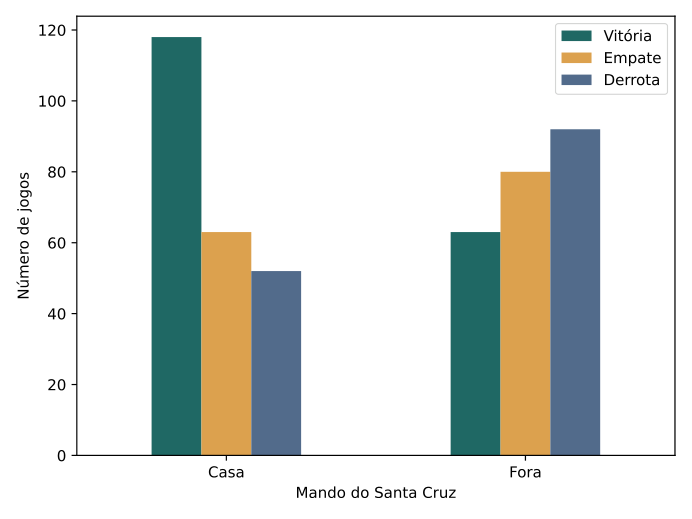

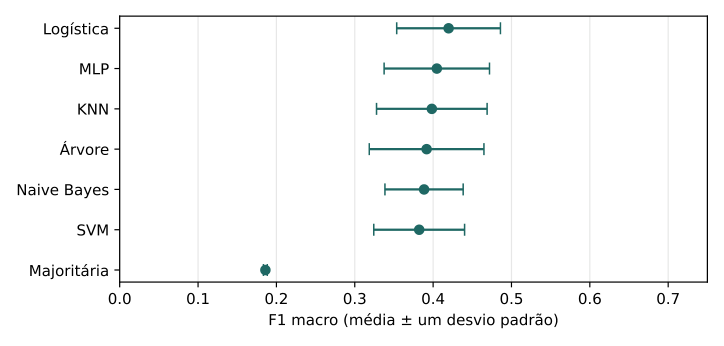

In [7]:
# Conta os resultados dentro e fora de casa.
mando = pd.crosstab(base["mando"], y)[classes]
ax = mando.rename(index={"C":"Casa", "F":"Fora"}).plot.bar(rot=0, color=["#206864", "#dca14e", "#526b8b"])
ax.set(xlabel="Mando do Santa Cruz", ylabel="Número de jogos")
ax.legend(["Vitória", "Empate", "Derrota"])
plt.tight_layout()
plt.savefig(pasta / "mando.pdf")
plt.show()
plt.close()

fig, ax = plt.subplots(figsize=(6.7, 3.2))
# Mostra a média e a variação entre folds.
ax.errorbar(melhores["f1_mean"], melhores["modelo"], xerr=melhores["f1_std"], fmt="o",
            color="#206864", capsize=4)
ax.set(xlabel="F1 macro (média ± um desvio padrão)", xlim=(0, 0.75))
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(pasta / "comparacao.pdf")
plt.show()
plt.close()


## 7. Papel do mando e média geral

Mantemos C=1 e os folds fixos enquanto alteramos as entradas da regressão logística. A última tabela resume, entre folds, a média das 18 configurações por fold.

In [8]:
# Mantém o modelo fixo e altera as entradas.
grupos = {"Completo": numericas + categoricas, "Sem mando": numericas + categoricas[1:], "Só mando": ["mando"]}
comparacao = []
for grupo, colunas in grupos.items():
    numeros = [c for c in colunas if c in numericas]
    categorias = [c for c in colunas if c in categoricas]
    transformador = ColumnTransformer([
        ("numericas", clone(preparo.transformers[0][1]), numeros),
        ("categoricas", clone(preparo.transformers[1][1]), categorias)
    ])
    for fold, (treino, teste) in enumerate(folds, start=1):
        modelo = make_pipeline(clone(transformador), LogisticRegression(C=1, max_iter=1000))
        modelo.fit(X.iloc[treino], y.iloc[treino])
        previsto = modelo.predict(X.iloc[teste])
        _, _, f1, _ = precision_recall_fscore_support(y.iloc[teste], previsto, average="macro", zero_division=0)
        comparacao.append([grupo, fold, accuracy_score(y.iloc[teste], previsto), f1])

ablacao = pd.DataFrame(comparacao, columns=["atributos", "fold", "acuracia", "f1"])
ablacao.to_csv(pasta / "efeito_do_mando.csv", index=False)
print(ablacao.groupby("atributos")[["acuracia", "f1"]].agg(["mean", "std"]).round(3))
# Resume as 18 configurações sem incluir a referência.
geral = detalhes[detalhes["modelo"] != "Majoritária"].groupby("fold")[metricas].mean()
geral.agg(["mean", "std"]).to_csv(pasta / "media_geral.csv")


          acuracia            f1       
              mean    std   mean    std
atributos                              
Completo     0.443  0.066  0.420  0.066
Sem mando    0.404  0.066  0.392  0.071
Só mando     0.449  0.063  0.350  0.049


## 8. Efeito da escala no KNN

Com k=21, repetimos os mesmos testes retirando apenas a normalização mínimo–máximo. Os demais passos permanecem iguais.

In [9]:
efeito_escala = []
for escala in ["Com escala", "Sem escala"]:
    preparo_knn = clone(preparo)
    if escala == "Sem escala":
        # Retira somente a normalização para medir seu efeito.
        preparo_knn.set_params(numericas__minmaxscaler="passthrough")
    for fold, (treino, teste) in enumerate(folds, start=1):
        knn = make_pipeline(clone(preparo_knn), KNeighborsClassifier(n_neighbors=21))
        knn.fit(X.iloc[treino], y.iloc[treino])
        previsto = knn.predict(X.iloc[teste])
        _, _, f1, _ = precision_recall_fscore_support(y.iloc[teste], previsto, average="macro", zero_division=0)
        efeito_escala.append([escala, fold, accuracy_score(y.iloc[teste], previsto), f1])

escala_knn = pd.DataFrame(efeito_escala, columns=["preparo", "fold", "acuracia", "f1"])
escala_knn.to_csv(pasta / "efeito_da_escala.csv", index=False)
print(escala_knn.groupby("preparo")[["acuracia", "f1"]].agg(["mean", "std"]).round(3))


           acuracia            f1       
               mean    std   mean    std
preparo                                 
Com escala    0.436  0.066  0.398  0.071
Sem escala    0.333  0.057  0.308  0.056
